# momentum_solve 최적화 1회차 — build_z 타일 전치 전/후 비교

**변경**: z 스윕 밴드 조립을 전용 커널 `build_kernel_z`(공유 메모리 (j,k) 타일 전치)로 분리 — `src/equation/momentum/system/system.cu`.
필드를 k 연속으로 읽고 밴드에 j 연속으로 쓴다. 계수 식(`sweep_band`)은 그대로라 결과는 비트 동일해야 한다 (게이트: 스모크 FINAL 0.01503 / 46.0360).

| 꼬리표 | 바이너리 | 하드웨어 |
|---|---|---|
| `h200m`, `v100m`, `a100` | 변경 전 (`rbc_nob_pre_buildz`) | H200 ×4, V100 ×4, A100 ×8 |
| `h200o`, `v100o`, `a100o` | 변경 후 (`build_kernel_z`) | 같은 노드 종류 |

그림은 저장하지 않는다 (노트북 출력만). 데이터: `apps/rbc_nob/scalability/out/`.

In [ ]:
import csv, glob, os, re
from collections import defaultdict
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullFormatter, PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "scalability", "out"))

HW_NAME = {"h200": "H200", "a100": "A100", "v100": "V100"}
VERSION = {"m": "before", "o": "after", "": "before"}          # 꼬리표 접미사 → 버전 (a100 = 전, a100o = 후)
VER_COLOR = {"before": "#9a9a96", "after": "#2a78d6"}          # 전 = 회색(기준), 후 = 파랑
HW_COLOR = {"h200": "#2a78d6", "a100": "#eb6834", "v100": "#1baf7a"}
COMPONENTS = ["dU", "dV", "dW"]
EVENTS_PER_COMPONENT = ["build_x", "tdma_x", "scatter_x", "build_y", "tdma_y", "scatter_y",
                        "build_z", "tdma_z", "scatter_z", "halo", "wall_ghost", "couple_rhs"]
EVENTS_POST = ["block_couple_v", "halo_dV", "wall_ghost_dV", "block_couple_u", "add_increment"]
EVENTS = EVENTS_PER_COMPONENT + EVENTS_POST
TOP = ["step_total", "momentum_solve", "scalar_solve", "momentum_rhs", "pressure_solve"]

def load_runs(out_dir=OUT_DIR):
    """{(hw, ver, mode, n, np): [ {phase: max_ms} ]} — momentum 세부 구간이 있는 런만"""
    runs = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(out_dir, "scal_*", "phase_timing_*.csv"))):
        m = re.search(r"scal_(strong|weak)_(\d+)_np(\d+)/phase_timing_([a-z0-9]+)_(\d+)_r(\d+)\.csv$", path)
        if not m:
            continue
        ph = {}
        with open(path) as fh:
            for row in csv.reader(l for l in fh if not l.startswith("#")):
                if row[0] != "phase":
                    ph[row[0]] = float(row[3])
        if not any(k.startswith("momentum.") for k in ph):
            continue
        tag = m.group(4); hw = tag[:4]; suffix = tag[4:]
        if hw not in HW_NAME or suffix not in VERSION:
            continue
        runs[(hw, VERSION[suffix], m.group(1), int(m.group(2)), int(m.group(3)))].append(ph)
    return runs

runs = load_runs()
cases = {k: sorted(v, key=lambda r: r["step_total"])[len(v) // 2] for k, v in runs.items()}

def event_time(ph, event, component=None):
    if event in EVENTS_POST:
        return ph.get(f"momentum.post.{event}", 0.0)
    comps = [component] if component else COMPONENTS
    return sum(ph.get(f"momentum.{c}.{event}", 0.0) for c in comps)

print(f"{len(cases)} cases")
for k in sorted(cases):
    print(f"  {k[0]:5s} {k[1]:6s} {k[2]:6s} {k[3]}^3 np{k[4]:<2d}  step {cases[k]['step_total']:7.1f}  momentum {cases[k]['momentum_solve']:6.1f}  build_z {event_time(cases[k], 'build_z'):6.2f} ms/step  (x{len(runs[k])})")

30 cases
  h200  after  strong 256^3 np1   step    39.8  momentum   17.9  build_z   1.81 ms/step  (x2)
  h200  after  strong 256^3 np2   step    25.3  momentum   12.3  build_z   0.93 ms/step  (x2)
  h200  after  strong 256^3 np4   step    16.9  momentum    8.8  build_z   0.51 ms/step  (x2)
  h200  after  strong 512^3 np1   step   292.6  momentum  122.6  build_z  14.10 ms/step  (x2)
  h200  after  strong 512^3 np2   step   154.8  momentum   67.2  build_z   7.08 ms/step  (x2)
  h200  after  strong 512^3 np4   step    82.8  momentum   37.6  build_z   3.60 ms/step  (x2)
  h200  after  weak   256^3 np1   step    39.8  momentum   17.9  build_z   1.81 ms/step  (x2)
  h200  after  weak   256^3 np2   step    42.5  momentum   19.5  build_z   1.80 ms/step  (x2)
  h200  after  weak   256^3 np4   step    42.7  momentum   19.8  build_z   1.80 ms/step  (x2)
  h200  before strong 256^3 np1   step    41.7  momentum   19.7  build_z   3.67 ms/step  (x2)
  h200  before strong 256^3 np2   step    26.2  mom

## 1. 게이트 — 결과 불변

변경 전/후 같은 덱·같은 np 의 200 스텝 모니터 줄(t, dt, θ_c, Nu, Tmin/Tmax, 벽 Nu, D_×, max|U|)이 같아야 한다. 아래는 로그에서 직접 비교.
max|div| 열은 뺀다 — 1e-15 자리의 리덕션 순서 잡음으로 변경 전 런끼리도 흔들린다.

In [ ]:
LOG_DIR = os.path.join(OUT_DIR, "..", "log")
def monitor_line(tag, name, step=200):
    for path in sorted(glob.glob(os.path.join(LOG_DIR, f"{name}_*_r1.log"))):
        job = re.search(r"_(\d+)_r1\.log$", path).group(1)
        env = glob.glob(os.path.join(OUT_DIR, f"environment_{tag}_{job}.txt"))
        if not env:
            continue
        with open(path) as fh:
            for line in fh:
                if re.match(rf"^\s+{step}\s", line):
                    return line.rstrip()
    return None

for hw, before, after in (("h200", "h200m", "h200o"), ("v100", "v100m", "v100o"), ("a100", "a100", "a100o")):
    for name in ("scal_strong_256_np1", "scal_strong_256_np4", "scal_strong_512_np1"):
        b, a = monitor_line(before, name), monitor_line(after, name)
        if b is None or a is None:
            continue
        cols = lambda line: line.split()[1:3] + line.split()[4:13]   # max|div|(리덕션 순서 잡음, 1e-15 자리)·sec/step 열 제외
        same = cols(b) == cols(a)
        print(f"[{HW_NAME[hw]}] {name}: {'SAME' if same else 'DIFFERENT'}")
        if not same:
            print("  before:", b); print("  after: ", a)

[H200] scal_strong_256_np1: SAME
[H200] scal_strong_256_np4: SAME
[H200] scal_strong_512_np1: SAME
[V100] scal_strong_256_np1: SAME
[V100] scal_strong_256_np4: SAME


## 2. 이벤트별 막대 — 전/후를 나란히 (np 마다 한 그림)

회색 = 변경 전, 파랑 = 변경 후. build_z(와 그 영향으로 바뀐 것)만 달라야 한다.

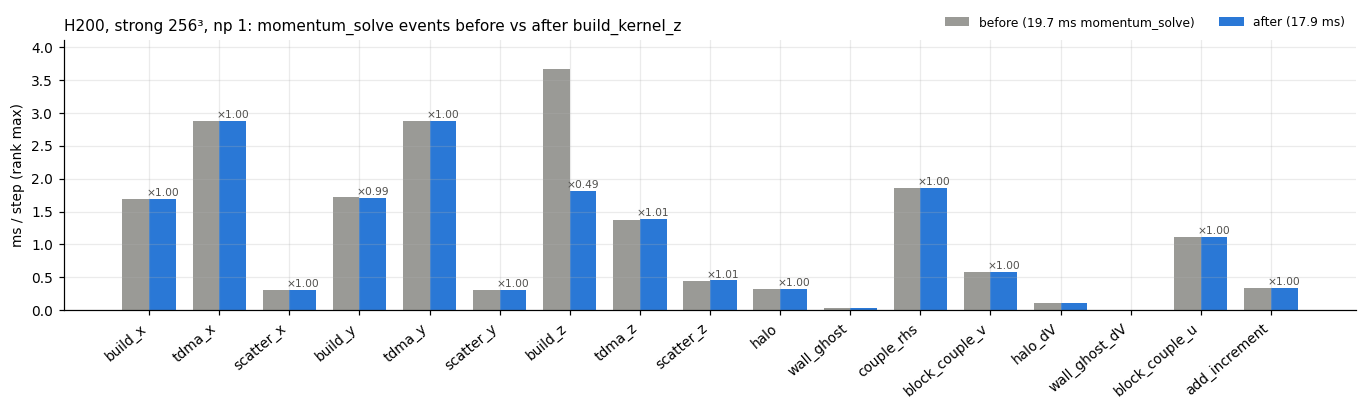

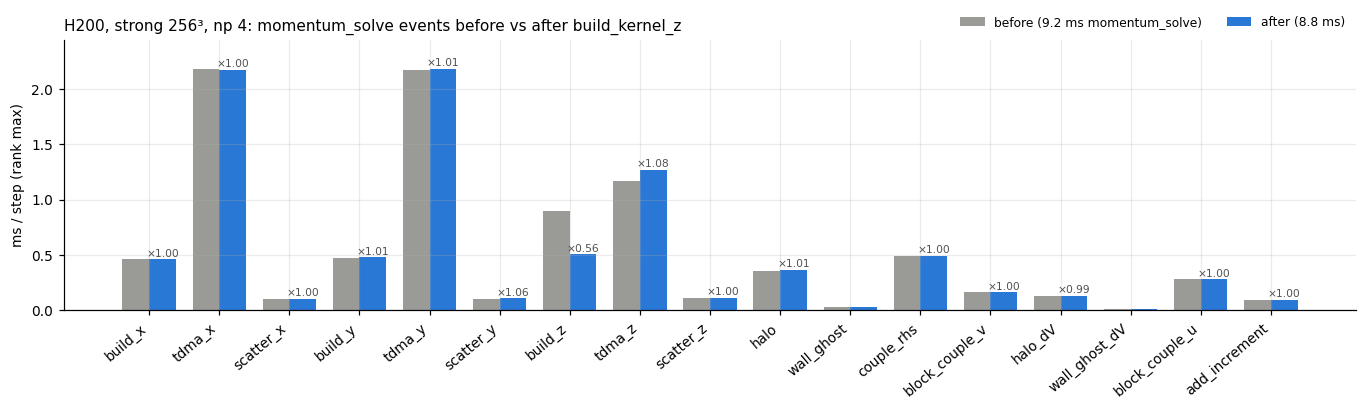

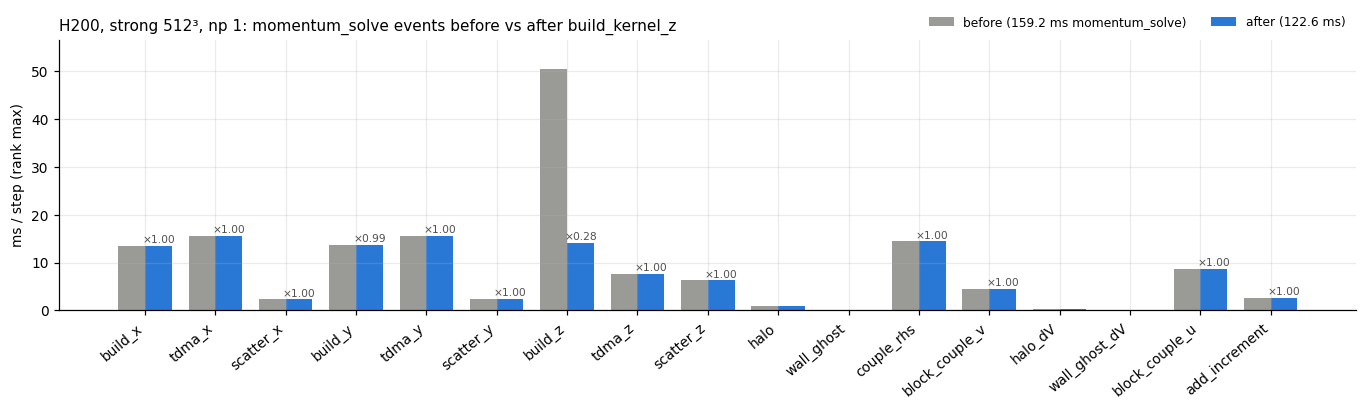

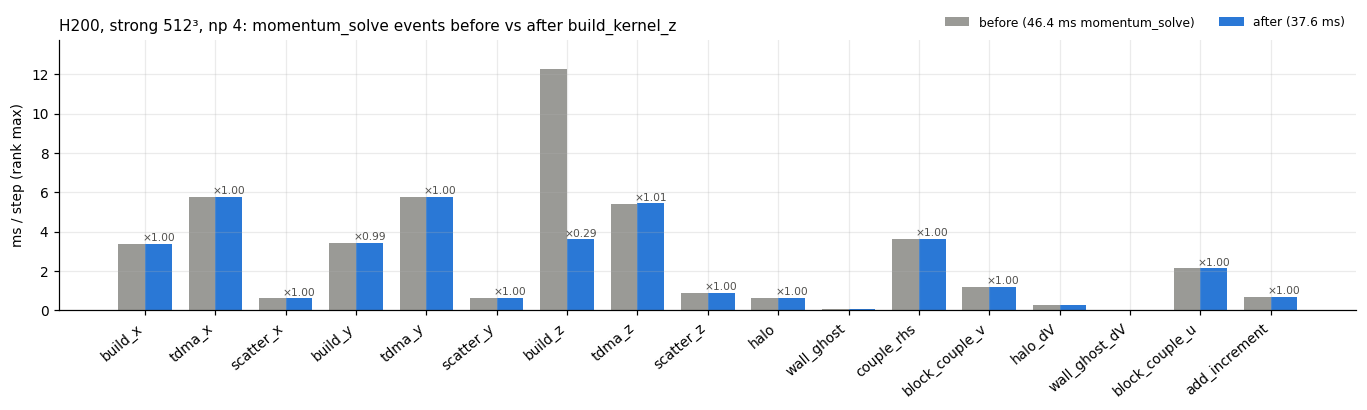

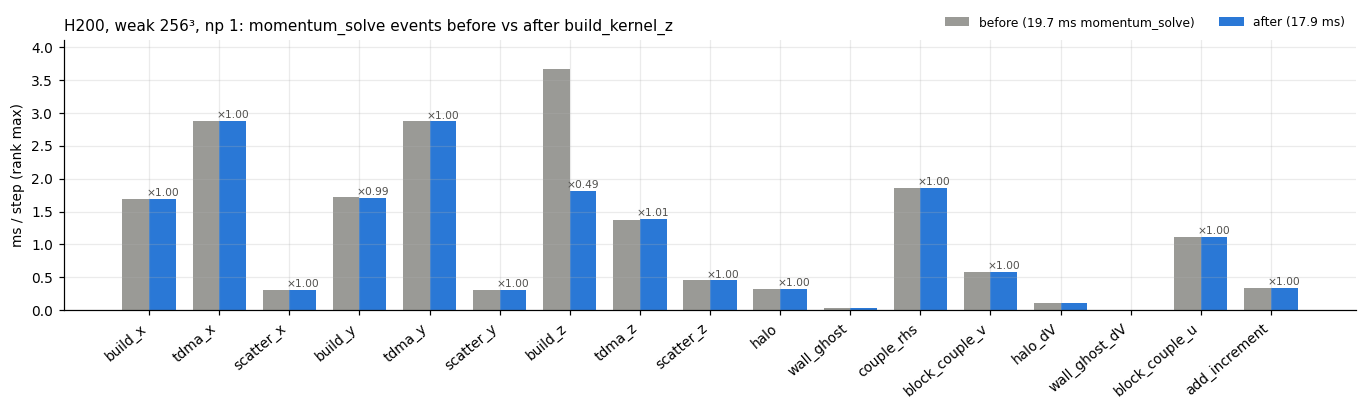

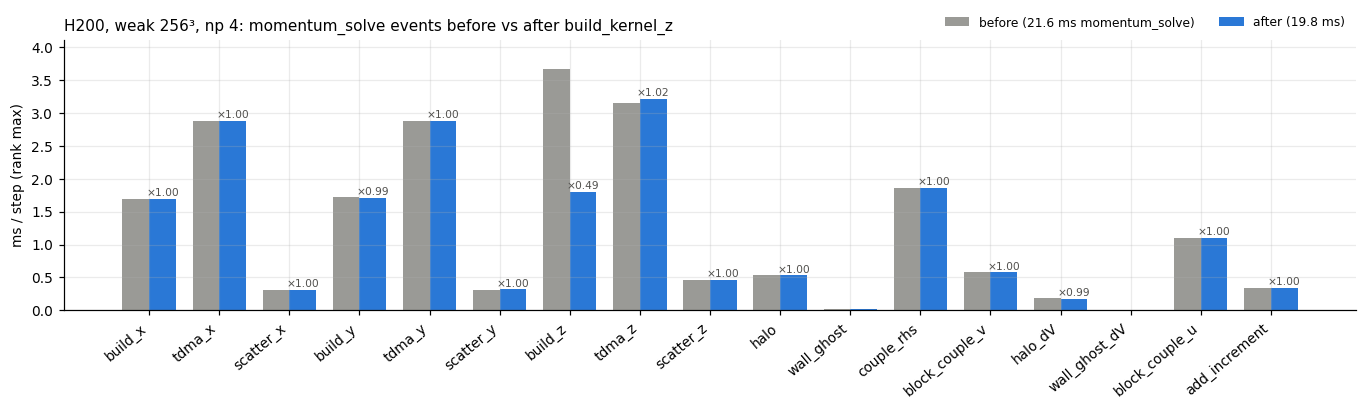

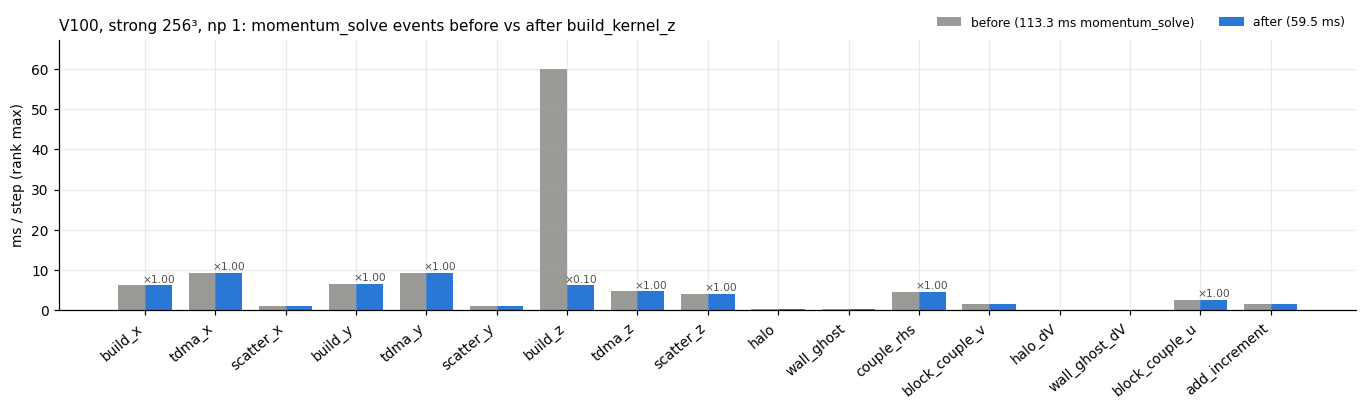

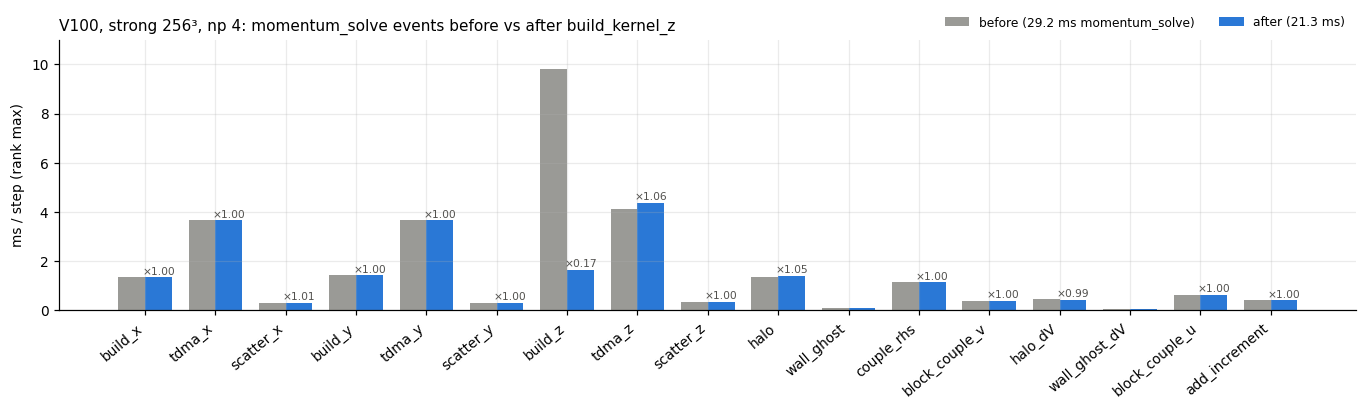

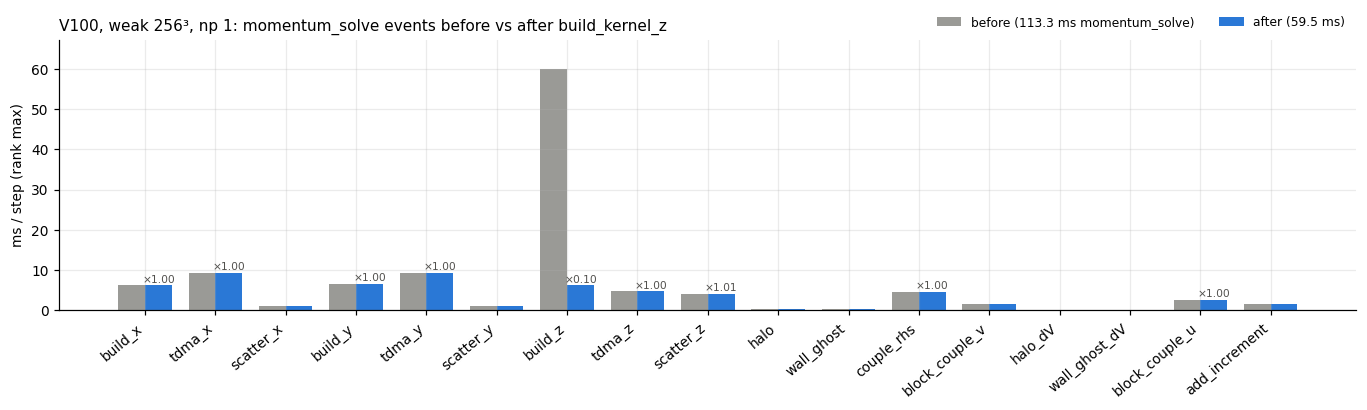

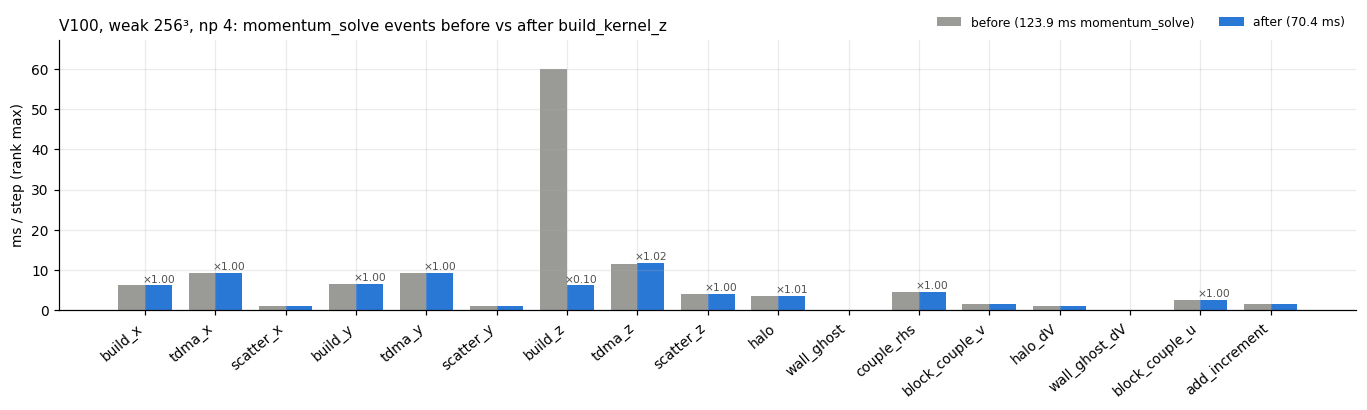

In [ ]:
def plot_before_after_events(mode, hw, n, np_):
    kb, ka = (hw, "before", mode, n, np_), (hw, "after", mode, n, np_)
    if kb not in cases or ka not in cases:
        return
    fig, ax = plt.subplots(figsize=(12.5, 3.8))
    xs = np.arange(len(EVENTS)); w = 0.38
    vb = np.array([event_time(cases[kb], e) for e in EVENTS]); va = np.array([event_time(cases[ka], e) for e in EVENTS])
    ax.bar(xs - w / 2, vb, w, color=VER_COLOR["before"], label=f"before ({cases[kb]['momentum_solve']:.1f} ms momentum_solve)")
    ax.bar(xs + w / 2, va, w, color=VER_COLOR["after"], label=f"after ({cases[ka]['momentum_solve']:.1f} ms)")
    for x, b, a in zip(xs, vb, va):
        if b > 0.03 * vb.max():
            ax.annotate(f"×{a / b:.2f}", (x + w / 2, a), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7, color="#52514e")
    ax.set_xticks(xs); ax.set_xticklabels(EVENTS, rotation=40, ha="right"); ax.set_ylabel("ms / step (rank max)")
    ax.set_title(f"{HW_NAME[hw]}, {mode} {n}³, np {np_}: momentum_solve events before vs after build_kernel_z", fontsize=10, loc="left")
    ax.set_ylim(0, max(vb.max(), va.max()) * 1.12)
    ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
    plt.tight_layout()

for hw in ("h200", "a100", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 4, 8):
                plot_before_after_events(mode, hw, n, np_)
plt.show()

## 3. 스텝 전체와 상위 구간 — 전/후 (np 별)

step_total, momentum_solve, scalar_solve, momentum_rhs, pressure_solve 의 전/후. build_z 는 momentum_solve 안에만 있으니
scalar_solve 등은 그대로여야 한다 (z 조립의 같은 문제가 scalar 에도 남아 있다 — 다음 회차).

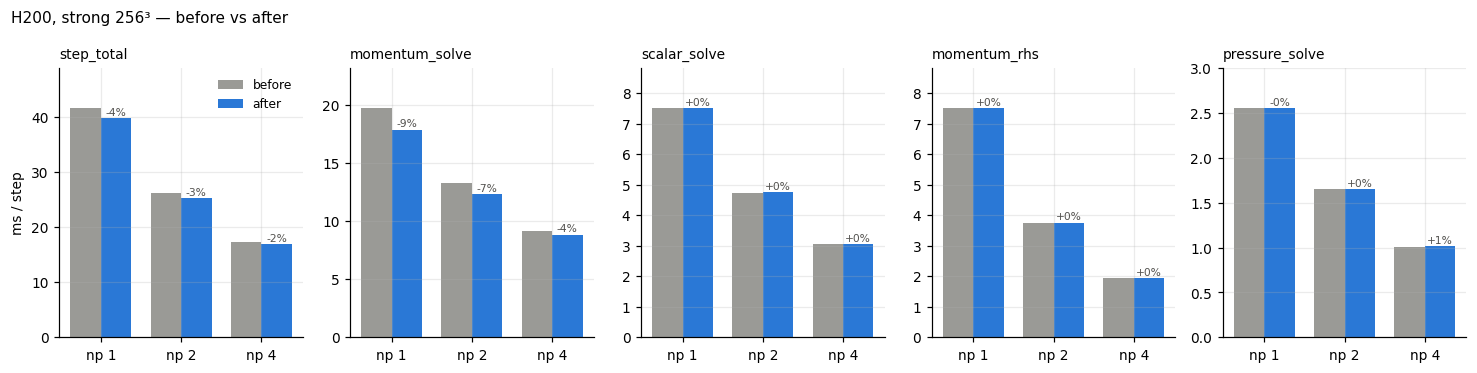

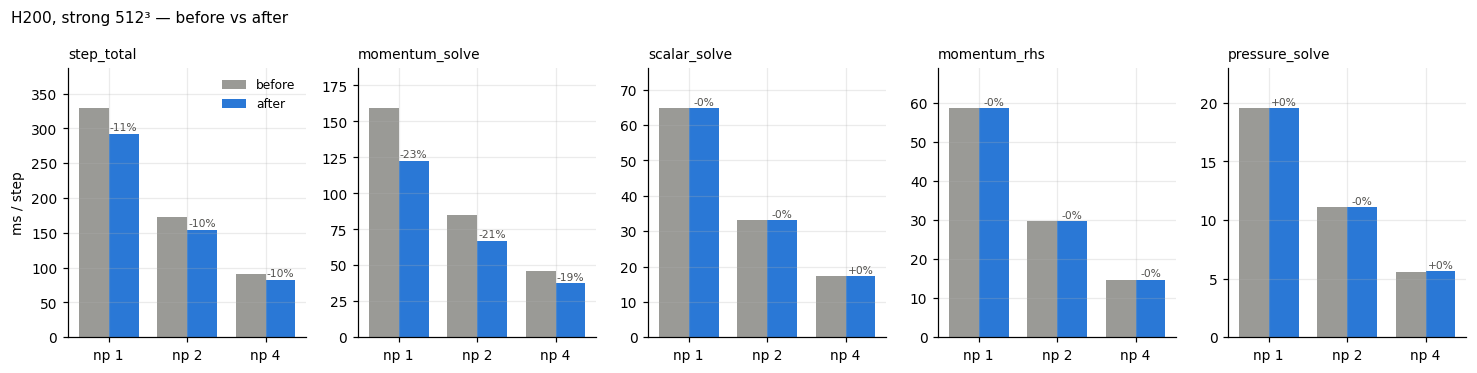

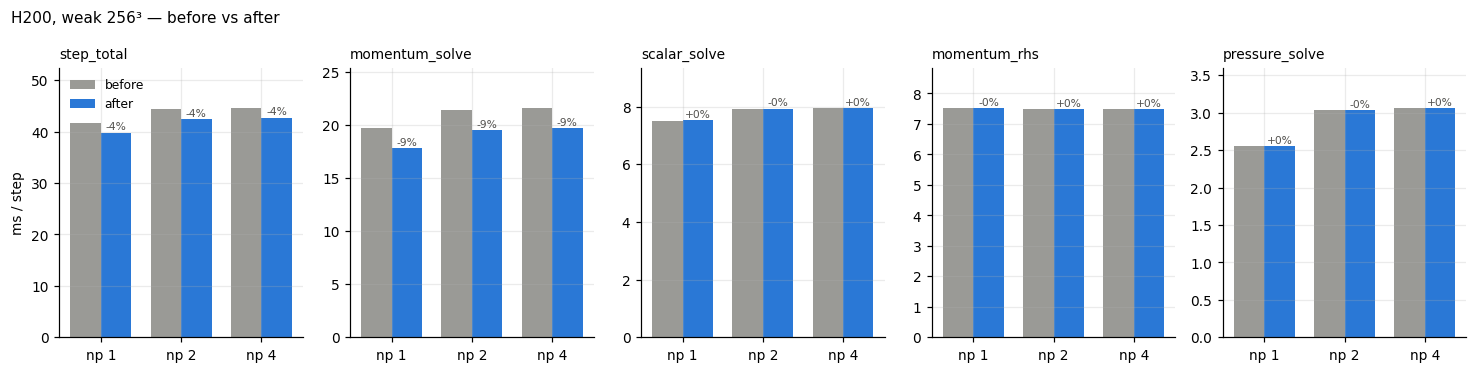

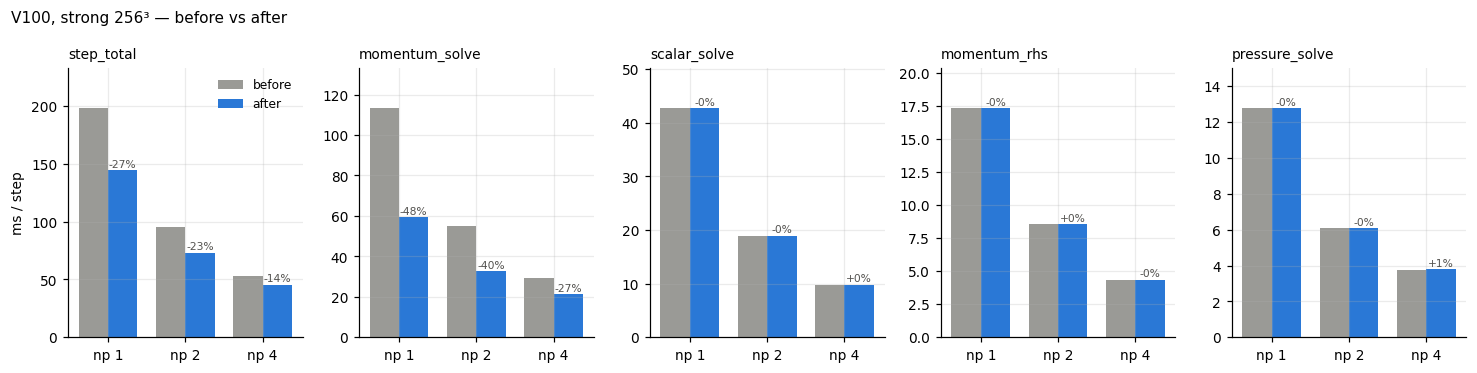

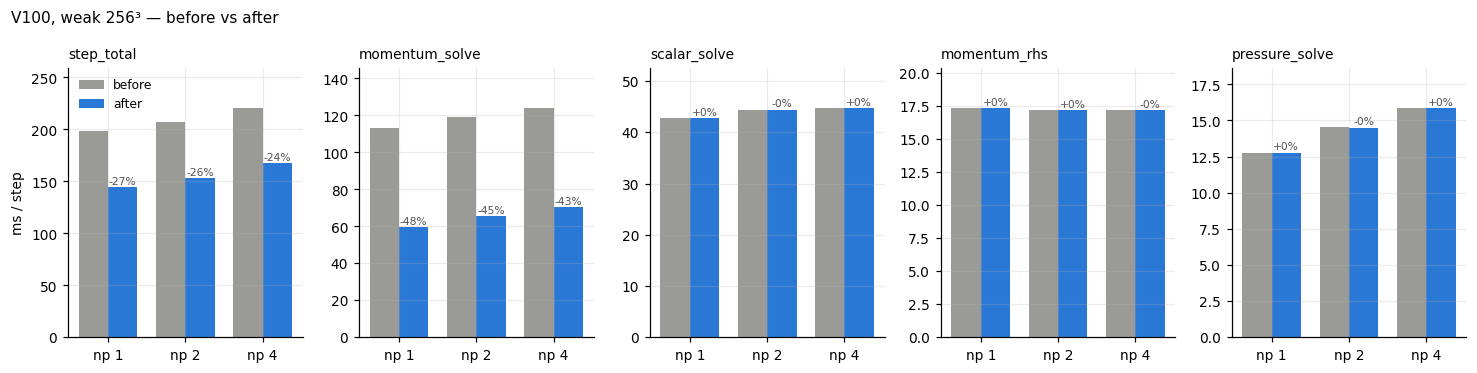

In [ ]:
def plot_top_before_after(mode, hw, n):
    nps = sorted({k[4] for k in cases if k[:4] in ((hw, "before", mode, n), (hw, "after", mode, n))})
    if not nps:
        return
    fig, axes = plt.subplots(1, len(TOP), figsize=(2.7 * len(TOP), 3.4))
    for ax, phase in zip(axes, TOP):
        xs = np.arange(len(nps)); w = 0.38
        for off, ver in ((-w / 2, "before"), (w / 2, "after")):
            vals = [cases.get((hw, ver, mode, n, p), {}).get(phase, np.nan) for p in nps]
            ax.bar(xs + off, vals, w, color=VER_COLOR[ver], label=ver)
        for x, p in zip(xs, nps):
            b = cases.get((hw, "before", mode, n, p), {}).get(phase); a = cases.get((hw, "after", mode, n, p), {}).get(phase)
            if b and a:
                ax.annotate(f"{100 * (a / b - 1):+.0f}%", (x + w / 2, a), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7, color="#52514e")
        ax.set_xticks(xs); ax.set_xticklabels([f"np {p}" for p in nps]); ax.set_title(phase, fontsize=9, loc="left")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
    axes[0].set_ylabel("ms / step"); axes[0].legend(frameon=False)
    fig.suptitle(f"{HW_NAME[hw]}, {mode} {n}³ — before vs after", fontsize=10, x=0.01, ha="left")
    fig.tight_layout()

for hw in ("h200", "a100", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            plot_top_before_after(mode, hw, n)
plt.show()

## 4. Scaling 곡선 — 전/후 (step_total 과 build_z)

왼쪽 열 step_total, 오른쪽 열 build_z. 점선 = 이상선. 색 = 하드웨어, 선 = 전(점선 마커 비움) / 후(실선).

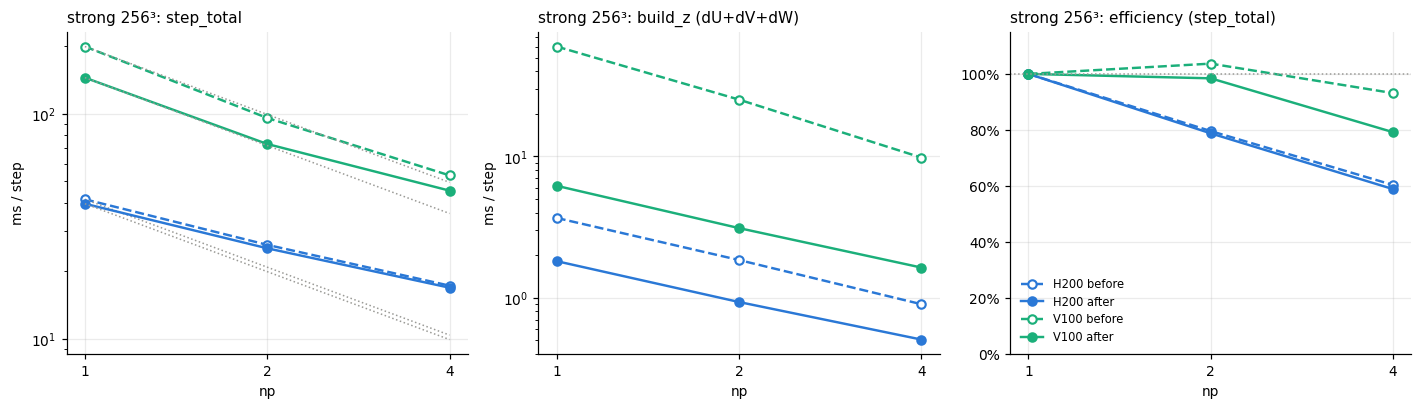

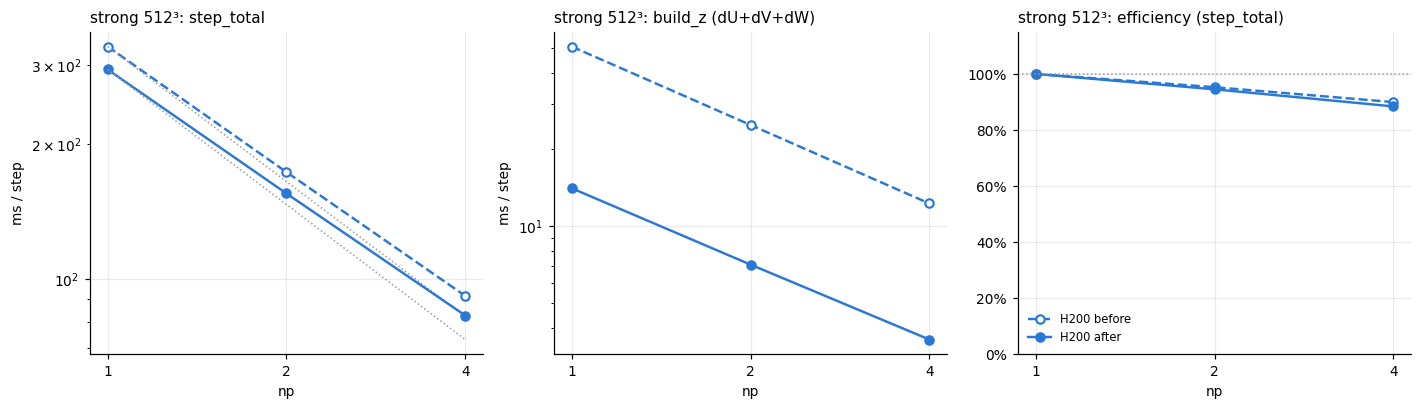

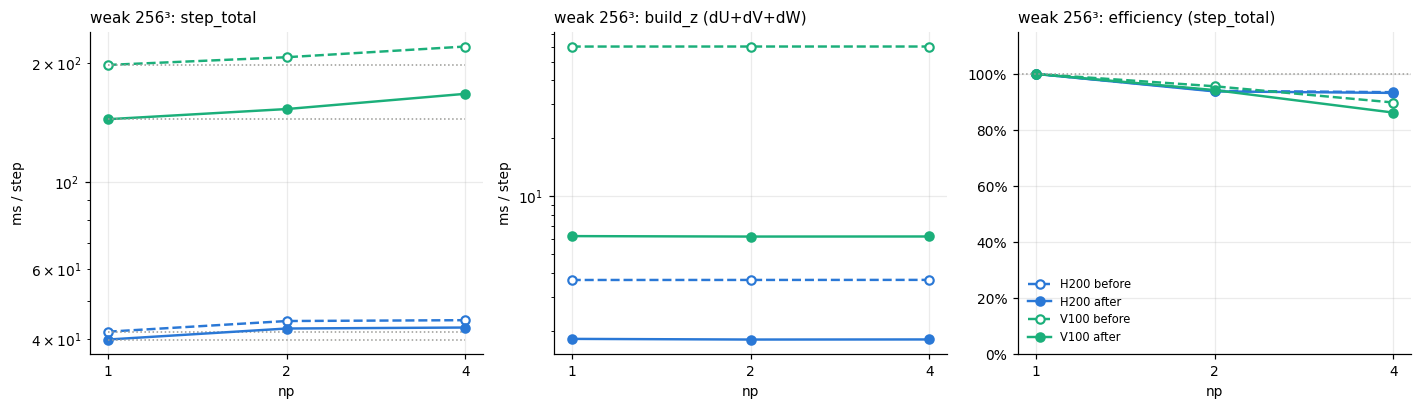

In [ ]:
def series(hw, ver, mode, n, phase=None, event=None):
    keys = sorted(k for k in cases if k[:4] == (hw, ver, mode, n))
    x = np.array([k[4] for k in keys], float)
    y = np.array([cases[k][phase] if phase else event_time(cases[k], event) for k in keys])
    return x, y

def plot_scaling_before_after(mode, n):
    hws = sorted({k[0] for k in cases if k[2:4] == (mode, n)})
    if not hws:
        return
    nps = sorted({k[4] for k in cases if k[2:4] == (mode, n)})
    fig, (ax_t, ax_z, ax_e) = plt.subplots(1, 3, figsize=(13, 3.8))
    for hw in hws:
        for ver, ls, mfc in (("before", "--", "white"), ("after", "-", HW_COLOR[hw])):
            x, y = series(hw, ver, mode, n, phase="step_total")
            if len(x) == 0:
                continue
            ax_t.plot(x, y, ls, marker="o", color=HW_COLOR[hw], lw=1.6, ms=5.5, mfc=mfc, mew=1.4, label=f"{HW_NAME[hw]} {ver}")
            if len(x) >= 2:
                ideal = y[0] * x[0] / x if mode == "strong" else np.full_like(y, y[0])
                ax_t.plot(x, ideal, ":", color="#9a9a96", lw=1)
                eff = (y[0] / y) / (x / x[0]) if mode == "strong" else y[0] / y
                ax_e.plot(x, eff, ls, marker="o", color=HW_COLOR[hw], lw=1.6, ms=5.5, mfc=mfc, mew=1.4, label=f"{HW_NAME[hw]} {ver}")
            xz, yz = series(hw, ver, mode, n, event="build_z")
            ax_z.plot(xz, yz, ls, marker="o", color=HW_COLOR[hw], lw=1.6, ms=5.5, mfc=mfc, mew=1.4)
    for ax, title in ((ax_t, "step_total"), (ax_z, "build_z (dU+dV+dW)")):
        ax.set_xscale("log", base=2); ax.set_yscale("log")
        ax.xaxis.set_major_locator(FixedLocator(nps)); ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xticklabels([str(p) for p in nps])
        ax.set_xlabel("np"); ax.set_ylabel("ms / step"); ax.set_title(f"{mode} {n}³: {title}", fontsize=10, loc="left")
    ax_e.set_xscale("log", base=2); ax_e.xaxis.set_major_locator(FixedLocator(nps)); ax_e.xaxis.set_minor_formatter(NullFormatter()); ax_e.set_xticklabels([str(p) for p in nps])
    ax_e.axhline(1, color="#9a9a96", ls=":", lw=1); ax_e.set_ylim(0, 1.15); ax_e.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax_e.set_xlabel("np"); ax_e.set_title(f"{mode} {n}³: efficiency (step_total)", fontsize=10, loc="left")
    ax_e.legend(frameon=False, loc="lower left", fontsize=7.5)
    fig.tight_layout()

for mode in ("strong", "weak"):
    for n in (256, 512):
        plot_scaling_before_after(mode, n)
plt.show()

## 5. 요약표

In [ ]:
print(f"{'hw':5s} {'mode':6s} {'n':4s} {'np':3s} | {'step before':>11s} {'after':>8s} {'gain':>6s} | {'momentum':>9s} {'after':>8s} | {'build_z':>8s} {'after':>8s} {'x':>6s}")
for hw in ("h200", "a100", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 2, 4, 8):
                kb, ka = (hw, "before", mode, n, np_), (hw, "after", mode, n, np_)
                if kb not in cases or ka not in cases:
                    continue
                b, a = cases[kb], cases[ka]
                bz_b, bz_a = event_time(b, "build_z"), event_time(a, "build_z")
                print(f"{hw:5s} {mode:6s} {n:<4d} {np_:<3d} | {b['step_total']:11.1f} {a['step_total']:8.1f} {100*(1-a['step_total']/b['step_total']):5.0f}% | "
                      f"{b['momentum_solve']:9.1f} {a['momentum_solve']:8.1f} | {bz_b:8.2f} {bz_a:8.2f} {bz_b/bz_a if bz_a>0 else float('nan'):6.1f}")

hw    mode   n    np  | step before    after   gain |  momentum    after |  build_z    after      x
h200  strong 256  1   |        41.7     39.8     4% |      19.7     17.9 |     3.67     1.81    2.0
h200  strong 256  2   |        26.2     25.3     3% |      13.2     12.3 |     1.85     0.93    2.0
h200  strong 256  4   |        17.3     16.9     2% |       9.2      8.8 |     0.90     0.51    1.8
h200  strong 512  1   |       329.2    292.6    11% |     159.2    122.6 |    50.59    14.10    3.6
h200  strong 512  2   |       172.8    154.8    10% |      85.1     67.2 |    24.94     7.08    3.5
h200  strong 512  4   |        91.5     82.8    10% |      46.4     37.6 |    12.28     3.60    3.4
h200  weak   256  1   |        41.7     39.8     4% |      19.7     17.9 |     3.67     1.81    2.0
h200  weak   256  2   |        44.4     42.5     4% |      21.4     19.5 |     3.67     1.80    2.0
h200  weak   256  4   |        44.6     42.7     4% |      21.6     19.8 |     3.67     1.80    2.0
